# Part 2: Cancer Classification and Model Improvement
**Floyd Maloba | ST10544961**  
**Programming for Data Analytics (PDAN8411) | 21 October 2026**

## 1. Introduction and objectives
The medical scheme in the brief wishes to speed up access to dreaded-disease benefits, initially focusing on cancer. This study evaluates a breast-mass classification prototype as an analytical component of that broader process. It does not predict policy eligibility, claim validity, benefit amount or processing time: those outcomes are absent from the data.

The objectives are to inspect data quality, identify patterns, evaluate feature subsets, compare classification algorithms, and interpret their errors. Predictions would require clinical and claims review; this experiment cannot authorise or reject benefits.

## 2. Dataset suitability and provenance
The supplied CSV contains the Wisconsin Diagnostic Breast Cancer measurements. A record-level audit confirmed that all 569 measurement-and-label records match scikit-learn's packaged dataset, ignoring row order. Original attribution is to Wolberg et al. (1993), UCI DOI: https://doi.org/10.24432/C5DW2B. No unverified Kaggle uploader is attributed.

UCI describes features derived from digitised fine-needle-aspirate images of breast masses, with B = benign and M = malignant. Thirty predictors summarise ten nuclear characteristics. This makes the dataset suitable for a basic supervised cancer-related classification exercise (Wolberg et al., 1993).

There are 357 benign (62.7%) and 212 malignant (37.3%) observations. The 32 original columns comprise 30 numerical predictors, a diagnosis and an exported row index. No missing values or duplicate observations were detected after excluding the index. A public benchmark supports reproducibility, but does not establish representativeness of the scheme's members. Claims and demographic context are unavailable.

## 3. Analysis plan
| Stage | Planned action and justification |
|---|---|
| Inspect and clean | Check labels, numeric types, missingness, duplicates and finite values; remove only a verified exported row index. |
| Split and explore | Reserve 20% using a stratified split, seed 42; examine distributions, grouped plots, correlations and IQR flags using training data. |
| Select features | Compare ANOVA-ranked top 10, top 20 and all 30 inside cross-validation pipelines; use mean malignant-class F1. |
| Train and compare | Compare a majority baseline, scaled L2 logistic regression and a 300-tree random forest using five stratified folds. |
| Evaluate and report | Explain accuracy, precision, recall, F1, ROC-AUC and confusion counts; report limitations, implications and references. |

This final documented plan includes the feature-selection completion added during review. The original test results had already been viewed; the extension uses training-fold scores only, but an independent external evaluation remains necessary.

## 4. Data preparation
The original dataframe is preserved as `df_raw`. A working copy removes the exported index only after verifying consecutive row numbers, strips the `x.` prefix and renames `y` to `diagnosis`. Index removal prevents record order from becoming a spurious predictor.

In [1]:
import pandas as pd

# Load the CSV from the same folder as your notebook.
# Preserve the original data in df_raw.
df_raw = pd.read_csv("brca.csv")

# Create a working copy for preparation.
df = df_raw.copy()

# Remove the exported index only if it contains consecutive row numbers.
if "Unnamed: 0" in df.columns:
    expected_index = list(range(1, len(df) + 1))

    if df["Unnamed: 0"].tolist() == expected_index:
        df = df.drop(columns="Unnamed: 0")

# Remove the x. prefix and give the target a descriptive name.
df.columns = df.columns.str.replace(r"^x\.", "", regex=True)
df = df.rename(columns={"y": "diagnosis"})

# Confirm that the cleaned dataframe is ready.
print("Cleaned shape:", df.shape)
print("Diagnosis counts:")
print(df["diagnosis"].value_counts())

Cleaned shape: (569, 31)
Diagnosis counts:
diagnosis
B    357
M    212
Name: count, dtype: int64


In [2]:
# Recheck quality after excluding the exported index; unique row numbers can hide duplicates.
print('Raw shape:', df_raw.shape)
print('Prepared shape:', df.shape)
print('Missing values:', int(df.isna().sum().sum()))
print('Duplicate observations:', int(df.duplicated().sum()))
assert not df.duplicated().any(), 'Investigate repeated observations before splitting.'
display(df.describe().T)

Raw shape: (569, 32)
Prepared shape: (569, 31)
Missing values: 0
Duplicate observations: 0


,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture_mean,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter_mean,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area_mean,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness_mean,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness_mean,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity_mean,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave_pts_mean,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry_mean,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
fractal_dim_mean,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


## 5. Target encoding and train–test split

The predictor matrix, X, contains the 30 numerical measurements.
The target, y, contains diagnosis labels encoded as B = 0 and M = 1.
M is therefore the positive class for precision, recall and F1-score.

The data is divided into 455 training observations and 114 test
observations using an 80:20 split. Stratification approximately
preserves the diagnosis proportions in both subsets.

A fixed random seed makes the split reproducible. Subsequent exploratory
analysis and model comparison use the training subset. The test subset
is reserved for final evaluation.

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Create a folder beside the notebook to store tables and figures.
output_dir = Path("assignment_outputs")
output_dir.mkdir(exist_ok=True)

# Confirm the target contains only the two expected diagnosis labels.
assert df["diagnosis"].isin(["B", "M"]).all(), (
    "Unexpected diagnosis label detected."
)

# Separate predictors from the outcome.
# Dropping diagnosis prevents the model from receiving the answer as an input.
X = df.drop(columns="diagnosis").copy()

# Encode the outcome: B = 0 and M = 1.
y = df["diagnosis"].map({"B": 0, "M": 1})

# Stop execution if an unexpected predictor issue is detected.
assert X.shape[1] == 30, "Expected 30 measurement features."
assert X.select_dtypes(include="number").shape[1] == 30
assert not X.isna().any().any(), "Missing predictor values detected."
assert np.isfinite(X.to_numpy()).all(), "Infinite values detected."

# Reserve 20% for final testing.
# stratify preserves approximate class proportions.
# random_state makes the split repeatable.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Create a training-only dataframe for exploratory group comparisons.
train_eda = X_train.copy()
train_eda["diagnosis"] = y_train.map({0: "B", 1: "M"})

print(f"Training observations: {len(X_train)}")
print(f"Test observations: {len(X_test)}")
print("Target coding: B = 0; M = 1")

# Save descriptive statistics calculated from the training predictors.
X_train.describe().T.to_csv(
    output_dir / "training_descriptive_statistics.csv"
)

Training observations: 455
Test observations: 114
Target coding: B = 0; M = 1


## 6. Exploratory data analysis

Histograms and boxplots examine six selected predictors covering size,
texture, shape and measurement variability. Mean and median reference
lines help identify asymmetry.

Grouped boxplots compare selected measurements between diagnosis
classes. A Pearson correlation heatmap examines linear relationships
among the ten mean measurements.

Skewness and potential outlier counts are calculated for every predictor.
The 1.5 × IQR rule flags unusual values; these observations are retained
because a statistical outlier is not automatically a recording error.

All analysis in this section uses the training subset. Tables and
figures are saved for reporting.

Training-group means:


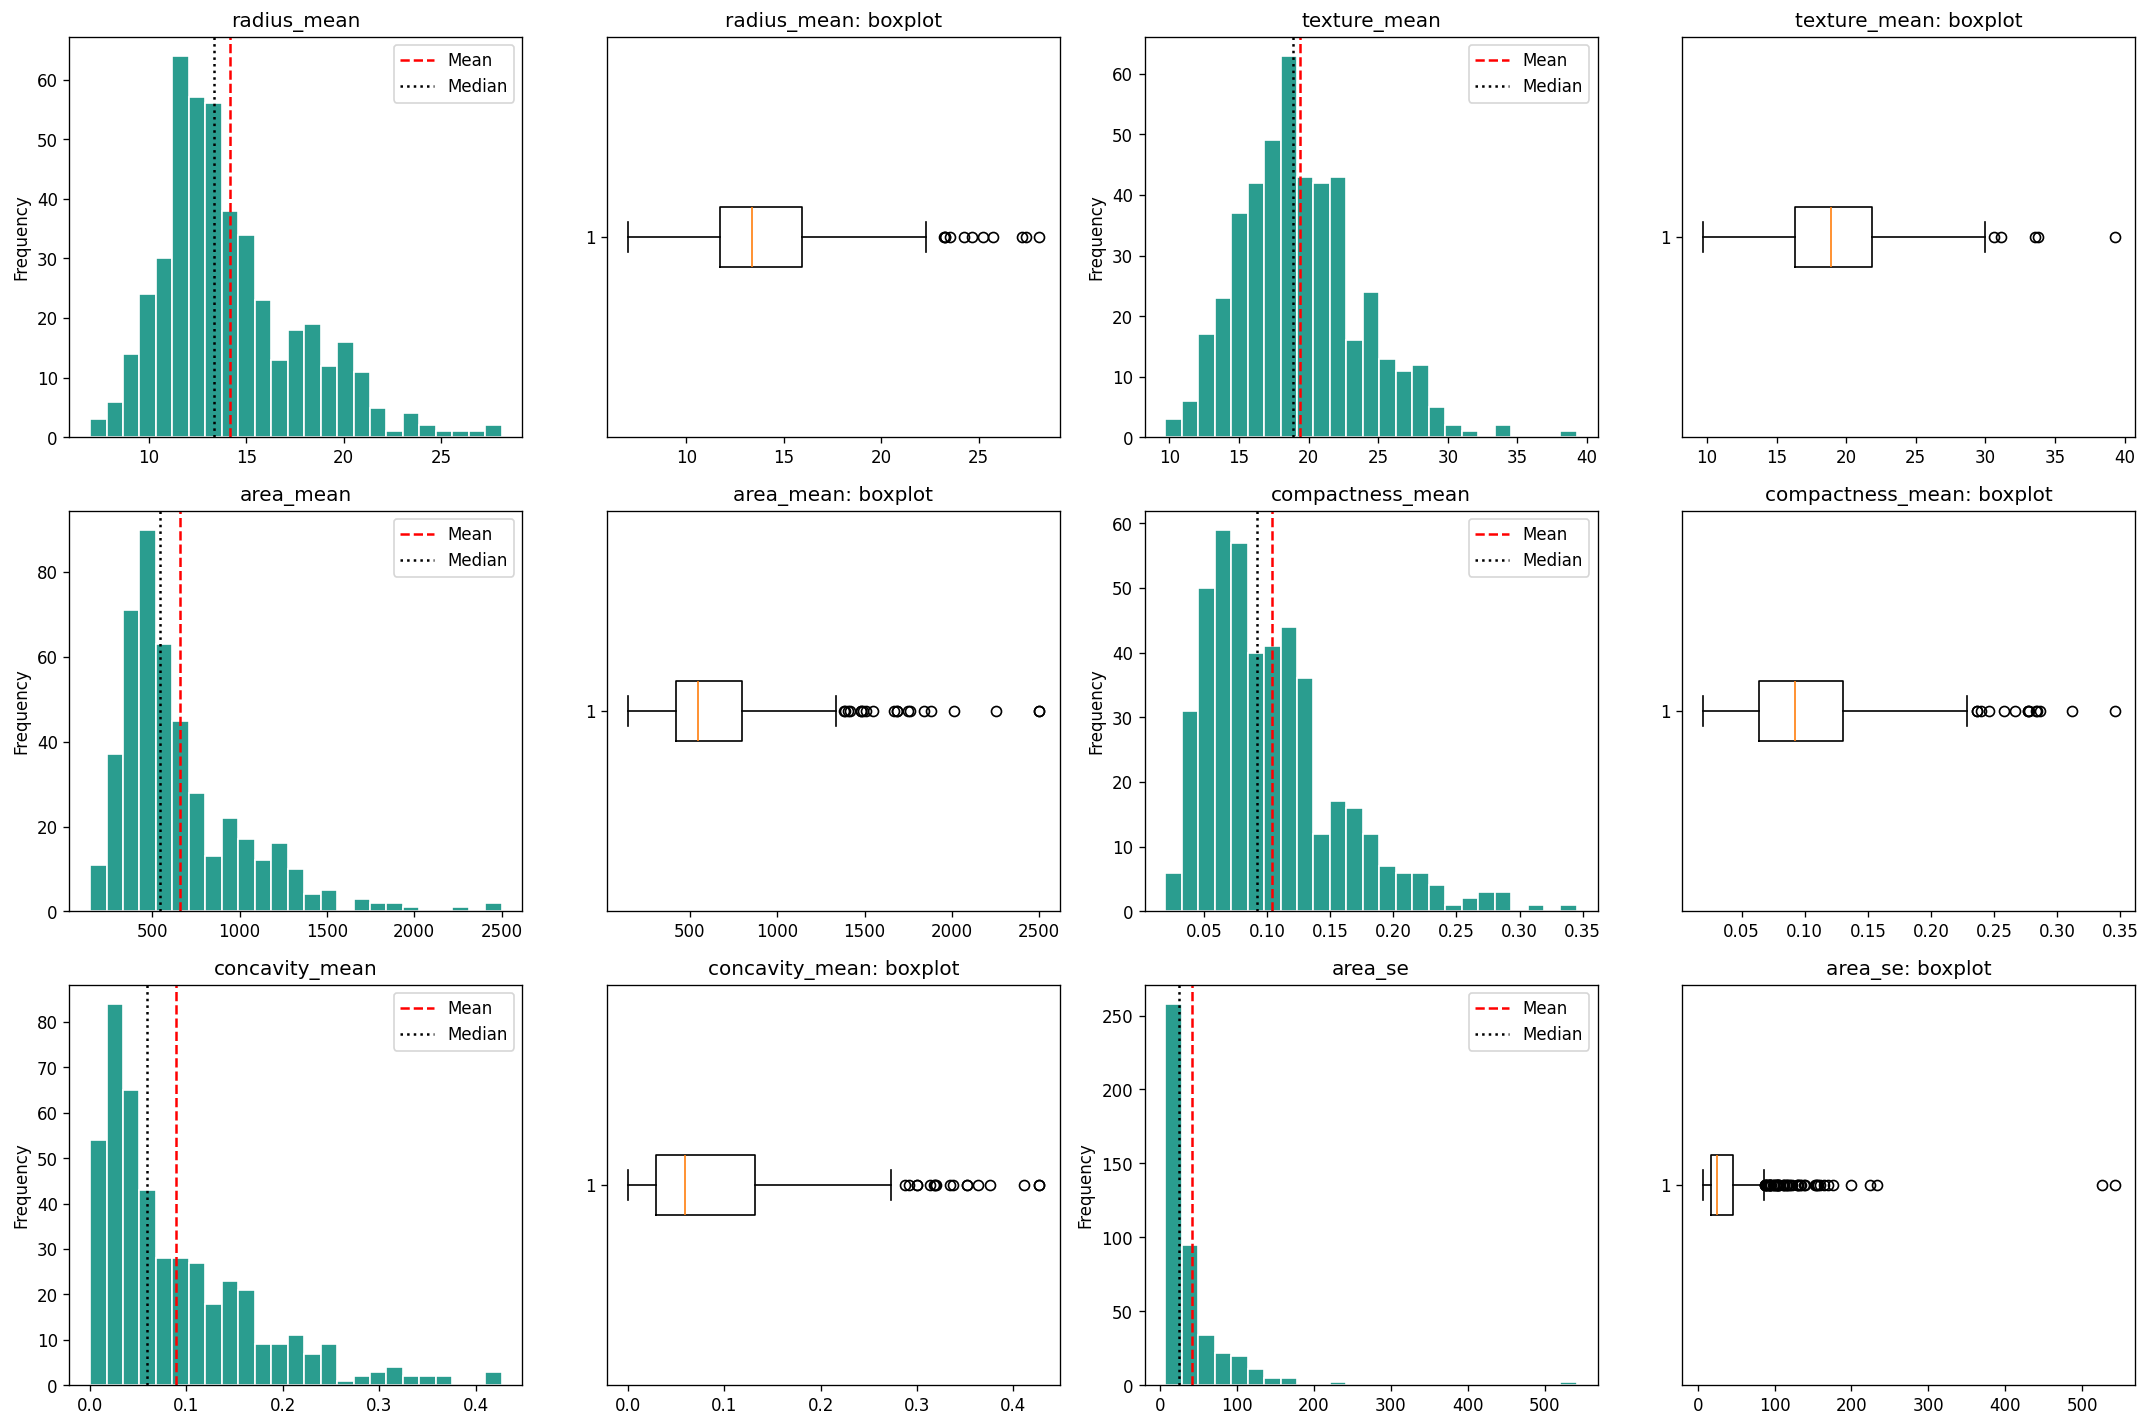

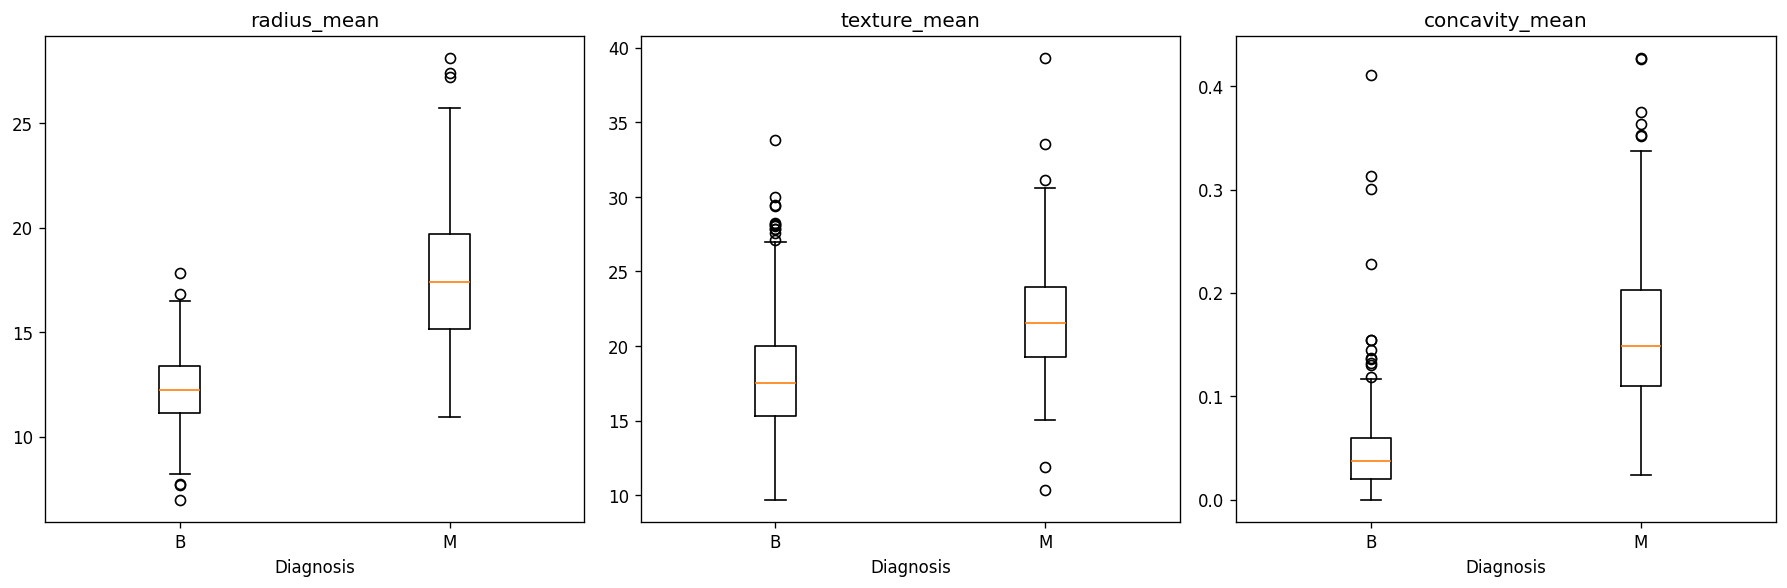

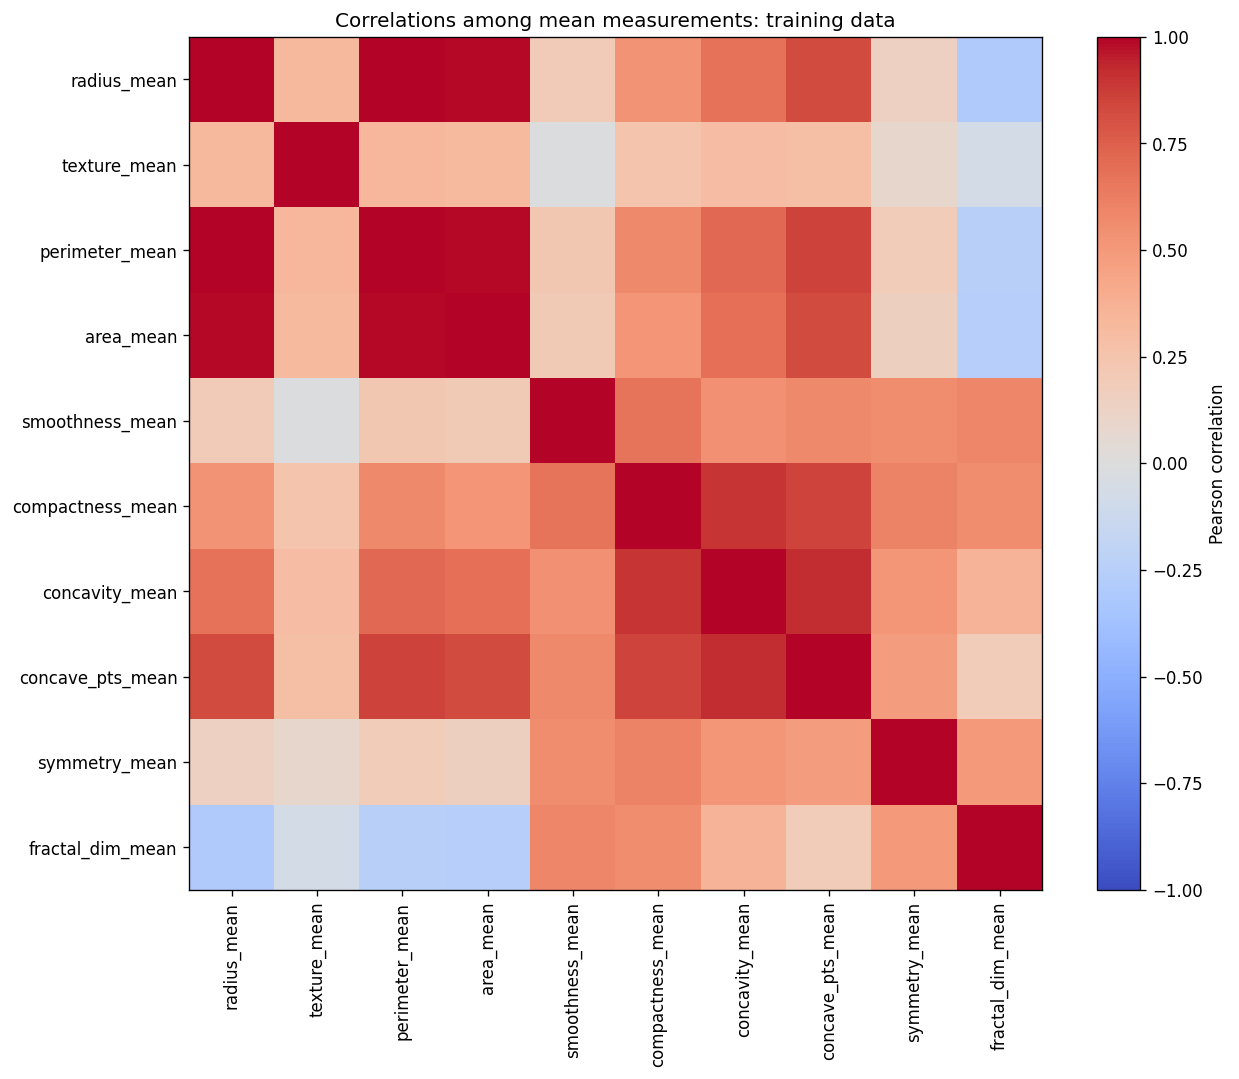

,mean,median,skewness,potential_outliers
area_se,41.2791,24.8700,5.4971,53
concavity_se,0.0320,0.0259,5.3911,24
fractal_dim_se,0.0038,0.0031,4.0852,23
perimeter_se,2.9116,2.3100,3.5168,34
radius_se,0.4112,0.3274,3.1811,31
smoothness_se,0.0069,0.0063,2.4594,20
symmetry_se,0.0204,0.0187,2.2453,22
area_worst,890.5692,683.4000,1.9027,21
texture_se,1.2179,1.1390,1.8092,15
compactness_se,0.0253,0.0202,1.7388,24


,radius_mean,texture_mean,area_mean,compactness_mean,concavity_mean,area_se
diagnosis,,,,,,
B,12.1555,18.0486,463.8568,0.0786,0.0461,21.3519
M,17.5368,21.7129,987.6994,0.1461,0.1614,74.6864


In [4]:
# Choose features covering different measurement characteristics.
features = [
    "radius_mean",
    "texture_mean",
    "area_mean",
    "compactness_mean",
    "concavity_mean",
    "area_se"
]

# Create one histogram and one boxplot for each selected feature.
fig, axes = plt.subplots(3, 4, figsize=(18, 12))

for i, feature in enumerate(features):
    row = i // 2
    col = (i % 2) * 2
    values = X_train[feature]

    # Histogram: examine the shape of the distribution.
    axes[row, col].hist(
        values,
        bins=25,
        color="#2A9D8F",
        edgecolor="white"
    )

    # Compare mean and median to help assess asymmetry.
    axes[row, col].axvline(
        values.mean(),
        color="red",
        linestyle="--",
        label="Mean"
    )
    axes[row, col].axvline(
        values.median(),
        color="black",
        linestyle=":",
        label="Median"
    )
    axes[row, col].set_title(feature)
    axes[row, col].set_ylabel("Frequency")
    axes[row, col].legend()

    # Boxplot: summarise spread and flag potential extreme values.
    axes[row, col + 1].boxplot(values, vert=False)
    axes[row, col + 1].set_title(f"{feature}: boxplot")

plt.tight_layout()
plt.savefig(output_dir / "feature_distributions.png", dpi=200)
plt.show()

# Compare feature distributions between B and M observations.
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

comparison_features = [
    "radius_mean", "texture_mean", "concavity_mean"
]

for ax, feature in zip(axes, comparison_features):
    groups = [
        train_eda.loc[train_eda["diagnosis"] == label, feature]
        for label in ["B", "M"]
    ]

    ax.boxplot(groups)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["B", "M"])
    ax.set_title(feature)
    ax.set_xlabel("Diagnosis")

plt.tight_layout()
plt.savefig(output_dir / "diagnosis_comparisons.png", dpi=200)
plt.show()

# Calculate correlations among the ten mean measurements.
mean_features = [
    column for column in X_train.columns
    if column.endswith("_mean")
]
corr = X_train[mean_features].corr()

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(mean_features)))
ax.set_yticks(range(len(mean_features)))
ax.set_xticklabels(mean_features, rotation=90)
ax.set_yticklabels(mean_features)

fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Correlations among mean measurements: training data")

plt.tight_layout()
plt.savefig(output_dir / "correlation_heatmap.png", dpi=200)
plt.show()

# Calculate the interquartile range for every predictor.
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1

# Flag potential outliers without deleting observations.
outlier_flags = (
    (X_train < q1 - 1.5 * iqr)
    | (X_train > q3 + 1.5 * iqr)
)

# Combine distribution statistics into one table.
eda_summary = pd.DataFrame({
    "mean": X_train.mean(),
    "median": X_train.median(),
    "skewness": X_train.skew(),
    "potential_outliers": outlier_flags.sum()
}).sort_values("skewness", ascending=False)

display(eda_summary.round(4))
eda_summary.to_csv(output_dir / "eda_summary.csv")

print("Training-group means:")
display(
    train_eda.groupby("diagnosis")[features].mean().round(4)
)

### 6.1 Interpretation of the training data
`area_se` is strongly right-skewed (5.497), with mean 41.279 and median 24.870; 53 of 455 observations are flagged by its IQR rule. `area_mean` is also right-skewed (1.720). Radius and texture have smaller positive skewness (0.986 and 0.647). These findings support retaining unusual measurements for investigation rather than deleting them automatically. Standardisation changes scale, not skewness, and is itself sensitive to extreme values (scikit-learn developers, n.d.g).

The malignant group has higher training means for radius (17.537 versus 12.155), texture (21.713 versus 18.049) and concavity (0.1614 versus 0.0461). Grouped boxplots show overlap, so a single threshold cannot be assumed to separate all cases. These are predictive associations, not evidence of causation.

Radius correlates strongly with perimeter (r = 0.9978) and area (r = 0.9867). Their shared size information motivates the feature-subset comparison and regularisation. Correlated measurements also make individual coefficients difficult to interpret.

## 7. Feature selection and engineering
The exported index and diagnosis are excluded from predictors. No additional synthetic predictors are created. All 30 numerical features are considered initially.

ANOVA F-scores rank features by between-class separation relative to within-class variability. `SelectKBest(f_classif)` compares the top 10, top 20 and all 30 measurements inside each training fold, followed by standardisation and logistic regression. This avoids selecting variables using validation or test labels (scikit-learn developers, n.d.a; n.d.c).

F-scores are used as a screening heuristic, not causal evidence or formal significance claims: the predictors include skewness and correlations, and univariate ranking cannot assess feature interactions. The highest mean cross-validation F1 determines whether to reduce the feature count. The existing all-feature model is retained if it performs best.

In [5]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score

# Exactly the same training-only folds are used for each subset size.
selection_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
selection_scoring = {
    'accuracy': 'accuracy',
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': 'recall', 'f1': 'f1', 'roc_auc': 'roc_auc'
}
subset_rows = []
for k in [10, 20, 30]:
    # Feature ranking is fitted afresh inside each fold, never on X_test.
    candidate = Pipeline([
        ('select', SelectKBest(score_func=f_classif, k=k)),
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(C=1.0, solver='lbfgs', max_iter=3000, random_state=42))
    ])
    scores = cross_validate(candidate, X_train, y_train, cv=selection_cv,
                            scoring=selection_scoring, error_score='raise')
    subset_rows.append({'features': k,
        **{metric: scores['test_' + metric].mean() for metric in selection_scoring},
        'f1_std': scores['test_f1'].std()})

subset_results = pd.DataFrame(subset_rows)
display(subset_results.round(4))
subset_results.to_csv(output_dir / 'feature_subset_comparison.csv', index=False)
best_k = int(subset_results.loc[subset_results['f1'].idxmax(), 'features'])
print('Feature count selected from training cross-validation:', best_k)
assert best_k == 30, 'Feature decision differs: review downstream model and report.'

# Training-only full-data ranking is descriptive; it is not used to preselect CV inputs.
f_scores, _ = f_classif(X_train, y_train)
feature_ranking = pd.DataFrame({'feature': X_train.columns, 'F_score': f_scores})
feature_ranking = feature_ranking.sort_values('F_score', ascending=False)
display(feature_ranking.head(10).round(3))
feature_ranking.to_csv(output_dir / 'feature_ranking.csv', index=False)

Feature count selected from training cross-validation: 30


,features,accuracy,precision,recall,f1,roc_auc,f1_std
0,10,0.9538,0.9584,0.9176,0.9370,0.9851,0.0436
1,20,0.9692,0.9830,0.9353,0.9572,0.9954,0.0194
2,30,0.9736,0.9771,0.9529,0.9640,0.9958,0.0207


,feature,F_score
27,concave_pts_worst,733.725
22,perimeter_worst,717.246
20,radius_worst,692.861
7,concave_pts_mean,684.527
2,perimeter_mean,548.413
23,area_worst,522.189
0,radius_mean,511.275
3,area_mean,444.858
6,concavity_mean,397.592
26,concavity_worst,319.508


### 7.1 Selection outcome
The top-10 and top-20 pipelines achieve mean validation F1 of 0.9370 and 0.9572 respectively, compared with 0.9640 for all 30. The all-feature pipeline also has higher mean recall (0.9529 versus 0.9176 and 0.9353). Retaining all 30 is therefore an evidence-based outcome of feature selection, rather than an omitted selection step. These small, non-nested validation comparisons do not prove a statistically significant difference.

The top training F-scores are `concave_pts_worst` (733.725), `perimeter_worst` (717.246), `radius_worst` (692.861) and `concave_pts_mean` (684.527). Strong univariate association does not establish unique importance when predictors overlap.

## 8. Model development and comparison
Logistic regression suits a binary target, produces probability estimates and offers a relatively compact linear decision model. L2 regularisation penalises large coefficients; it does not remove all correlated predictors. Scaling is learned within folds, preventing preprocessing leakage (scikit-learn developers, n.d.a; n.d.d; n.d.g).

A random forest offers a nonlinear comparator and can represent interactions without scaling. Its greater complexity is not assumed to improve this small dataset; performance is measured (scikit-learn developers, n.d.f). A single decision tree may be less stable, while distance-based methods need careful scaling and can be affected by redundant dimensions. An ensemble comparison is sufficient for this basic exercise; these alternatives were not trained here.

Settings: logistic regression uses C=1.0, solver=lbfgs, a 3,000-iteration cap and seed 42. The forest uses 300 trees, minimum leaf size 2, square-root feature sampling and seed 42. Other settings remain at library defaults. No extensive hyperparameter search or threshold optimisation is claimed.

Five-fold stratified cross-validation on the 455 training observations uses mean malignant-class F1 for model selection. Stratification preserves approximate class proportions. Fold standard deviations describe variation, not confidence intervals. Selected CV scores are not an unbiased nested estimate of the entire selection procedure (scikit-learn developers, n.d.b).

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score

models = {
    # Reference model: always predict the most frequent training class.
    "Majority baseline": DummyClassifier(
        strategy="most_frequent"
    ),

    # Fit scaling and classification together within each training fold.
    "Logistic regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            C=1.0, solver="lbfgs",
            max_iter=3000,
            random_state=42
        ))
    ]),

    # Tree-based classifier for nonlinear relationships.
    "Random forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

# Use the same reproducible stratified folds for every candidate.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# zero_division=0 handles the baseline predicting no positive cases.
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score, zero_division=0
    ),
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

rows = []

for name, model in models.items():
    # Evaluate on held-out folds within the training subset.
    # Raise errors directly so failures are not silently ignored.
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        error_score="raise"
    )

    # Summarise the five validation scores for each metric.
    row = {"model": name}

    for metric in scoring:
        row[f"{metric}_mean"] = scores[
            f"test_{metric}"
        ].mean()

        row[f"{metric}_std"] = scores[
            f"test_{metric}"
        ].std()

    rows.append(row)

cv_results = pd.DataFrame(rows).set_index("model")
cv_results = cv_results.sort_values(
    "f1_mean", ascending=False
)

display(cv_results.round(4))
cv_results.to_csv(
    output_dir / "cross_validation_results.csv"
)

# Select using cross-validation, without consulting test performance.
# Keep the majority baseline as a reference, not a final candidate.
candidate_results = cv_results.drop(
    index="Majority baseline"
)

best_name = candidate_results.index[0]
best_model = models[best_name]

print(
    "Selected model by mean cross-validation F1:",
    best_name
)

Selected model by mean cross-validation F1: Logistic regression


,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
model,,,,,,,,,,
Logistic regression,0.9736,0.0149,0.9771,0.0280,0.9529,0.0399,0.9640,0.0207,0.9958,0.0047
Random forest,0.9582,0.0235,0.9534,0.0365,0.9353,0.0471,0.9434,0.0320,0.9875,0.0071
Majority baseline,0.6264,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000


### 8.1 Comparison outcome
Logistic regression achieves mean validation F1 of 0.9640 (SD 0.0207), exceeding the forest's 0.9434 (SD 0.0320). Mean recall is 0.9529 versus 0.9353. The baseline obtains 62.64% accuracy but zero malignant recall and F1, showing why accuracy alone is unsuitable. Logistic regression is selected by training cross-validation and refitted using all 455 training observations; test scores are not used to choose the winner.

## 9. Evaluation and interpretation
The original 114-observation test split contains 72 benign and 42 malignant cases. The selected classifier is evaluated at its default probability threshold of 0.5.

With malignant as positive: accuracy = (TP+TN)/N; precision = TP/(TP+FP); recall = TP/(TP+FN); F1 = 2PR/(P+R). ROC-AUC measures ranking discrimination across thresholds and is not accuracy or proof of calibrated probabilities (scikit-learn developers, n.d.e).

Recall is essential because missed malignant cases matter to the brief. Precision captures the review burden from false alerts. F1 balances the two without explicitly giving false negatives a greater cost. No clinical or financial cost matrix is available to set an operational threshold.

              precision    recall  f1-score   support

           B       0.96      0.99      0.97        72
           M       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114


RESULTS PARAGRAPH

Logistic regression was selected using the highest mean F1-score among the candidate classifiers in five-fold stratified cross-validation on the training set. On the reserved test set of 114 observations, it achieved accuracy of 96.5%, precision of 97.5%, recall of 92.9%, F1-score of 0.951, and ROC-AUC of 0.996. With M coded as the positive class, the confusion matrix contained 71 true negatives, 1 false positives, 3 false negatives and 39 true positives. False negatives represent M observations predicted as B. These results describe performance on this dataset and split; they do not establish suitability for clinical use.

Outputs saved in: /wo

accuracy     0.9649
precision    0.9750
recall       0.9286
f1           0.9512
roc_auc      0.9960
Name: Test score, dtype: float64

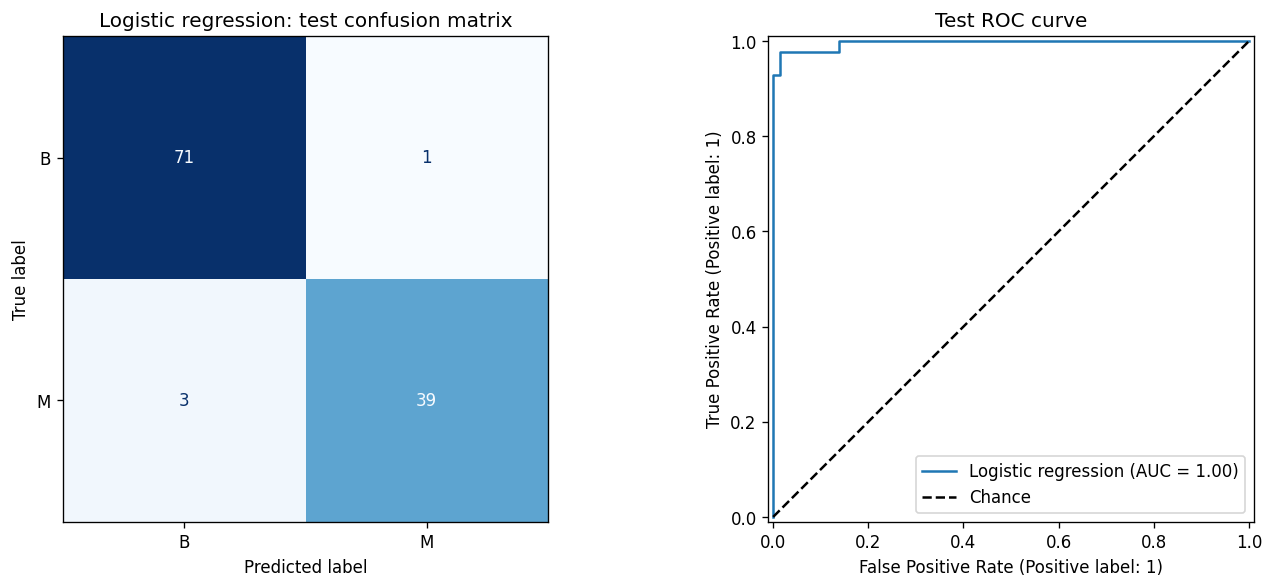

In [7]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Refit the selected pipeline using all training observations.
# Both scaling and model fitting use training data only.
best_model.fit(X_train, y_train)

# Generate class predictions using the default decision rule.
predictions = best_model.predict(X_test)

# Extract estimated probabilities for class M, encoded as 1.
probabilities = best_model.predict_proba(X_test)[:, 1]

# Calculate complementary measures of test performance.
test_scores = {
    "accuracy": accuracy_score(y_test, predictions),
    "precision": precision_score(
        y_test, predictions, zero_division=0
    ),
    "recall": recall_score(
        y_test, predictions, zero_division=0
    ),
    "f1": f1_score(
        y_test, predictions, zero_division=0
    ),
    "roc_auc": roc_auc_score(
        y_test, probabilities
    )
}

display(
    pd.Series(test_scores, name="Test score").round(4)
)

# Display performance separately for both diagnosis classes.
print(classification_report(
    y_test,
    predictions,
    labels=[0, 1],
    target_names=["B", "M"],
    zero_division=0
))

# Explicit label order ensures consistent interpretation.
cm = confusion_matrix(
    y_test, predictions, labels=[0, 1]
)
tn, fp, fn, tp = cm.ravel()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["B", "M"]
).plot(
    ax=axes[0],
    cmap="Blues",
    colorbar=False
)
axes[0].set_title(
    f"{best_name}: test confusion matrix"
)

# Plot discrimination across thresholds using probabilities.
RocCurveDisplay.from_predictions(
    y_test,
    probabilities,
    name=best_name,
    ax=axes[1]
)

axes[1].plot(
    [0, 1], [0, 1], "k--", label="Chance"
)
axes[1].legend()
axes[1].set_title("Test ROC curve")

plt.tight_layout()
plt.savefig(
    output_dir / "final_model_evaluation.png",
    dpi=200
)
plt.show()

# Build a factual paragraph directly from calculated results.
results_paragraph = (
    f"{best_name} was selected using the highest mean F1-score "
    f"among the candidate classifiers in five-fold stratified "
    f"cross-validation on the training set. "
    f"On the reserved test set of {len(y_test)} observations, "
    f"it achieved accuracy of {test_scores['accuracy']:.1%}, "
    f"precision of {test_scores['precision']:.1%}, "
    f"recall of {test_scores['recall']:.1%}, "
    f"F1-score of {test_scores['f1']:.3f}, and "
    f"ROC-AUC of {test_scores['roc_auc']:.3f}. "
    f"With M coded as the positive class, the confusion matrix "
    f"contained {tn} true negatives, {fp} false positives, "
    f"{fn} false negatives and {tp} true positives. "
    f"False negatives represent M observations predicted as B. "
    f"These results describe performance on this dataset and "
    f"split; they do not establish suitability for clinical use."
)

print("\nRESULTS PARAGRAPH\n")
print(results_paragraph)

# Save numerical results and the generated paragraph for reporting.
pd.Series(test_scores).to_csv(
    output_dir / "test_scores.csv"
)

(output_dir / "results_paragraph.txt").write_text(
    results_paragraph,
    encoding="utf-8"
)

print(f"\nOutputs saved in: {output_dir.resolve()}")

### 9.1 Results and interpretation

Logistic regression correctly classified 110 of 114 test observations.

| Metric | Result |
|---|---:|
| Accuracy | 96.5% |
| Precision for M | 97.5% |
| Recall for M | 92.9% |
| F1-score for M | 0.951 |
| ROC-AUC | 0.996 |

| Actual class | Predicted B | Predicted M |
|---|---:|---:|
| B | 71 | 1 |
| M | 3 | 39 |

The model detected 39 of the 42 actual M observations, missing three.
These false negatives explain why accuracy alone is insufficient.

The ROC-AUC indicates strong discrimination across thresholds; it
does not imply 99.6% accuracy at the default decision threshold.

Results are limited by the small test subset, a single train–test
split and the absence of external validation.

## 10. Findings, recommendations and conclusion
The model correctly classifies 110 of 114 test observations. Three malignant cases are classified as benign and one benign case as malignant. Malignant recall is 92.86%; specificity is 98.61%. A high ROC-AUC does not remove errors at the chosen threshold.

For the medical scheme, this supports investigating an assisted review workflow, not automatic benefit decisions. The data contain diagnostic measurements rather than claims-processing outcomes, so no reduction in turnaround time, cost saving or benefit-eligibility accuracy has been demonstrated.

The three missed malignant cases are the main shortcoming. A future study should compare class weighting or a lower threshold using training-only validation and a stated cost or minimum-recall objective. More false positives may result. No threshold was changed after inspecting test errors. Feature-subset retraining was performed; it did not improve validation F1, so the original settings and all 30 features were retained.

Limitations include a small benchmark sample, correlated and skewed predictors, a single random split, no external validation and no evidence of representativeness for scheme members. The original test results had already been inspected before the final feature-selection audit; although that audit used training data only, the reported test result is not a new independent prospective evaluation. Cross-validation comparisons are non-nested and their differences are descriptive. StandardScaler is sensitive to outliers, and calibration was not tested.

Before operational use, validate on contemporary independent local data; assess subgroup performance and probability calibration; establish clinical oversight and claims-policy checks; and measure actual review turnaround time. Human review should remain responsible for decisions.

In conclusion, scaled regularised logistic regression outperformed the tested forest by training-fold F1. Explicit feature-subset checks supported all 30 predictors, and final test accuracy was 96.49%. The result demonstrates a functioning academic prototype, with important false-negative and generalisation limitations.

## 11. References
Wolberg, W., Mangasarian, O., Street, N. and Street, W. (1993). *Breast Cancer Wisconsin (Diagnostic) [Dataset]. UCI Machine Learning Repository.* Available at: https://doi.org/10.24432/C5DW2B (Accessed: 21 October 2026).

scikit-learn developers (n.d.a). *Common pitfalls and recommended practices.* Available at: https://scikit-learn.org/stable/common_pitfalls.html (Accessed: 21 October 2026).

scikit-learn developers (n.d.b). *Cross-validation: evaluating estimator performance.* Available at: https://scikit-learn.org/stable/modules/cross_validation.html (Accessed: 21 October 2026).

scikit-learn developers (n.d.c). *Feature selection.* Available at: https://scikit-learn.org/stable/modules/feature_selection.html (Accessed: 21 October 2026).

scikit-learn developers (n.d.d). *LogisticRegression.* Available at: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html (Accessed: 21 October 2026).

scikit-learn developers (n.d.e). *Metrics and scoring: quantifying the quality of predictions.* Available at: https://scikit-learn.org/stable/modules/model_evaluation.html (Accessed: 21 October 2026).

scikit-learn developers (n.d.f). *RandomForestClassifier.* Available at: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html (Accessed: 21 October 2026).

scikit-learn developers (n.d.g). *StandardScaler.* Available at: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html (Accessed: 21 October 2026).

In [8]:
# Record the execution environment to support reproducibility.
import sys, sklearn, matplotlib
print('Python:', sys.version.split()[0])
print('pandas:', pd.__version__)
print('NumPy:', np.__version__)
print('scikit-learn:', sklearn.__version__)
print('Matplotlib:', matplotlib.__version__)

Python: 3.12.14
pandas: 2.2.3
NumPy: 2.3.5
scikit-learn: 1.8.0
Matplotlib: 3.10.8
